# Waste Management AI: Object Detection

**Purpose:** This notebook is used to train an Object-Detection Model (YOLO26) for use on the Raspberry Pi. 

### Prototype classes
- `organic` → e.g.  **watermelon**
- `plastic` e.g.  **bottle**
- `other` →  e.g. **clothing, metals, etc**

### Pipeline
`data → labels → train/val/test split → pretrained YOLO → training → validation → error analysis → export → HPC`


## 0. Recommended prototype targets

These are **engineering targets**, not guaranteed results.

- **Minimum acceptable validation mAP50:** 0.80
- **Preferred validation mAP50:** ≥ 0.90
- **Target inference speed:** ≥ 20 FPS on the final robot computer
- **Camera:** 30 FPS
- **Deployment:** Raspberry Pi 5
- **Failure cases to test:** poor lighting, shadows, object partly hidden, objects touching/overlapping, small/far objects, unusual orientations, motion blur, dirty/crushed objects, confusing background, and false detections on field boards/floor.
  

## 1. Install the software

This installs Ultralytics for YOLO training and FiftyOne for downloading a small, filtered subset of Open Images.

We deliberately **do not download the full Open Images dataset**. It is enormous. We only request small subsets containing the classes we need for this prototype.


In [1]:
!pip install -U ultralytics fiftyone


  Obtaining dependency information for ultralytics from https://files.pythonhosted.org/packages/c4/3a/5ef847347eeedff4f006574aaf3b531e1915cdcd10eaac0d2ded93840413/ultralytics-8.4.156-py3-none-any.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 241.9 kB/s eta 0:00:00a 0:00:01
  Obtaining dependency information for numpy>=1.23.0 from https://files.pythonhosted.org/packages/b4/63/3de6a34ad7ad6646ac7d2f55ebc6ad439dbbf9c4370017c50cf403fb19b5/numpy-2.2.6-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata
  Using cached numpy-2.2.6-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 2.3 MB/s eta 0:00:0000:0100:010m
Using cached numpy-2.2.6-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.8 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
  Attempting uninsta

In [2]:
# MongoDB dependencies -> required by FiftyOne
# !apt-get update && apt-get install -y libcurl4 openssl procps
!chmod 1777 /tmp && apt-get update && apt-get install -y libcurl4 openssl procps

Hit:1 http://archive.ubuntu.com/ubuntu focal InRelease
Hit:2 http://security.ubuntu.com/ubuntu focal-security InRelease
Hit:3 http://archive.ubuntu.com/ubuntu focal-updates InRelease
Hit:4 http://archive.ubuntu.com/ubuntu focal-backports InRelease
Reading package lists... Done
Reading package lists... Done
Building dependency tree       
Reading state information... Done
libcurl4 is already the newest version (7.68.0-1ubuntu2.25).
openssl is already the newest version (1.1.1f-1ubuntu2.24).
procps is already the newest version (2:3.3.16-1ubuntu2.4).
0 upgraded, 0 newly installed, 0 to remove and 38 not upgraded.


In [3]:
# Fix numpy / pytorch compatibility issue

!pip install "numpy<2.0.0"

# Verify
import numpy as np
import torch

arr = np.zeros((1, 3, 64, 64), dtype=np.float32)
tensor = torch.from_numpy(arr)
print("Success! Tensor shape:", tensor.shape)

  Obtaining dependency information for numpy<2.0.0 from https://files.pythonhosted.org/packages/4b/d7/ecf66c1cd12dc28b4040b15ab4d17b773b87fa9d29ca16125de01adb36cd/numpy-1.26.4-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata
  Using cached numpy-1.26.4-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.2 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.6
    Uninstalling numpy-2.2.6:
      Successfully uninstalled numpy-2.2.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 4.14.0.94 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incomp

## 2. Imports and project configuration

This cell creates the folders used by the notebook and defines the three classes.

Class IDs must remain consistent:
- `0 = organic`
- `1 = plastic`
- `2 = others`


In [4]:
import os
from pathlib import Path

print (os.getcwd())
print(Path.cwd())
print (os.listdir())
print(Path("./content/waste_ai"))

/workspace
/workspace
['student_workspace.txt', '.ipynb_checkpoints', 'test_notebook.ipynb', 'Waste_AI_Training_Pipeline_Prototype.ipynb', 'Waste_AI_Training_Notebook.ipynb', 'content', 'Untitled.ipynb', 'waste_ai.zip', 'waste_ai', '__MACOSX', 'yolo26n.pt', 'runs', 'weights']
content/waste_ai


In [5]:
from pathlib import Path
import random
import shutil
import yaml
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

PROJECT = Path.cwd() / "waste_ai"
RAW_DIR = PROJECT / "raw"
DATASET_DIR = PROJECT / "dataset"
EXPORT_DIR = PROJECT / "exports"

for p in [RAW_DIR, DATASET_DIR, EXPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

CLASSES = ["organic", "plastic", "others"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASSES)}

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Project:", PROJECT)
print("Classes:", CLASS_TO_ID)


Project: /workspace/waste_ai
Classes: {'organic': 0, 'plastic': 1, 'others': 2}


## 3. Download a small public dataset subset

We use **Open Images V7** through FiftyOne.

For this prototype:
- `Bottle` → `plastic`
- `Watermelon` → `organic`
- `Clothing` → temporary `other` proxy

The download is intentionally small. You can increase the sample counts later.

Open Images provides bounding-box annotations, so this is suitable for object detection rather than just image classification.


In [6]:
import fiftyone as fo
import fiftyone.zoo as foz
import fiftyone.core.service as fos

# Force FiftyOne to shut down any dead service locks
fos.DatabaseService().stop()

# Test database initialization
dataset = fo.Dataset()
print("FiftyOne DB initialized successfully:", dataset)


def load_open_images_subset(class_name, max_samples=80, seed=SEED):
    name = "open-images-v7"
    print(f"Loading {max_samples} samples for {class_name}...")
    return foz.load_zoo_dataset(
        name,
        split="validation",
        label_types=["detections"],
        classes=[class_name],
        only_matching=True,
        max_samples=max_samples,
        shuffle=True,
        seed=seed,
    )

bottle_fo = load_open_images_subset("Bottle", max_samples=80, seed=42)
watermelon_fo = load_open_images_subset("Watermelon", max_samples=80, seed=43)
clothing_fo = load_open_images_subset("Clothing", max_samples=80, seed=44)

print("Bottle samples:", len(bottle_fo))
print("Watermelon samples:", len(watermelon_fo))
print("Clothing samples:", len(clothing_fo))


/opt/conda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Process 23193 (service/main.py --51-service db --multi) did not respond
FiftyOne DB initialized successfully: Name:        2026.09.19.21.35.15.459115
Media type:  None
Num samples: 0
Persistent:  False
Tags:        []
Sample fields:
    id:               fiftyone.core.fields.ObjectIdField
    filepath:         fiftyone.core.fields.StringField
    tags:             fiftyone.core.fields.ListField(fiftyone.core.fields.StringField)
    metadata:         fiftyone.core.fields.EmbeddedDocumentField(fiftyone.core.metadata.Metadata)
    created_at:       fiftyone.core.fields.DateTimeField
    last_modified_at: fiftyone.core.fields.DateTimeField
Loading 80 samples for Bottle...
Necessary images already downloaded
Existing download of split 'validation' is sufficient
Loading 'open-images-v7' split 'validation'
 100% |███████████████████| 80/80 [202.3ms elapsed, 0s remaining, 395.4 samples/s]     
Dataset 'open-images-v7-validation-80' created
Loading 80 samples for Watermelon...
Only found 27 (<8

## 4. Inspect the public data before training

Do not train blindly.

Look at a few examples and ask:
- Does the object look like what the robot camera will see?
- Are the boxes correct?
- Is the object too easy to detect because of a clean background?
- Are there weird examples that should be removed?

This inspection step becomes more important when you move to your real competition dataset.


In [7]:
# FiftyOne can open an interactive browser-style viewer in some Colab setups.
# If the viewer does not work in your runtime, continue with the saved dataset
# and inspect exported images later.

print("Open Images subsets loaded successfully.")
print("Next, export the relevant bounding boxes into our 3-class YOLO dataset.")


Open Images subsets loaded successfully.
Next, export the relevant bounding boxes into our 3-class YOLO dataset.


## 5. Create YOLO train/validation/test folders

Ultralytics YOLO expects images and matching label files.

Each label line is:

`class_id x_center y_center width height`

with all coordinates normalized from 0 to 1.


In [8]:
for split in ["train", "val", "test"]:
    (DATASET_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (DATASET_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

print("YOLO dataset folders created.")


YOLO dataset folders created.


## 6. Export FiftyOne detections into our three-class dataset

The function below:
1. reads each image,
2. keeps only the requested Open Images class,
3. converts the bounding box to YOLO format,
4. assigns our competition-prototype class ID,
5. copies the image into the dataset.

We use a deterministic split so the same source image is not randomly moved around every run.


In [9]:
def export_fiftyone_class(dataset, source_class, target_class, max_images=None):
    target_id = CLASS_TO_ID[target_class]
    samples = list(dataset)
    if max_images:
        samples = samples[:max_images]

    exported = []
    for sample in samples:
        src = Path(sample.filepath)
        if not src.exists():
            continue

        # Make a unique filename so datasets from different sources do not collide.
        out_name = f"{target_class}_{src.stem}_{src.suffix.lower().replace('.', '')}{src.suffix.lower()}"

        # Save image temporarily; split happens later.
        tmp_dir = RAW_DIR / target_class
        tmp_dir.mkdir(parents=True, exist_ok=True)
        out_img = tmp_dir / out_name
        if not out_img.exists():
            shutil.copy2(src, out_img)

        detections = []
        # Open Images is loaded into FiftyOne with detection labels.
        if hasattr(sample, "ground_truth") and sample.ground_truth is not None:
            for det in sample.ground_truth.detections:
                if det.label.lower() == source_class.lower():
                    x, y, w, h = det.bounding_box
                    xc = x + w / 2
                    yc = y + h / 2
                    detections.append(
                        f"{target_id} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}"
                    )

        # Some FiftyOne Open Images imports use another field name.
        if not detections:
            for field_name in sample.field_names:
                value = sample[field_name]
                if hasattr(value, "detections"):
                    for det in value.detections:
                        if det.label.lower() == source_class.lower():
                            x, y, w, h = det.bounding_box
                            detections.append(
                                f"{target_id} {x+w/2:.6f} {y+h/2:.6f} {w:.6f} {h:.6f}"
                            )
                    if detections:
                        break

        if detections:
            label_path = out_img.with_suffix(".txt")
            label_path.write_text("\n".join(detections) + "\n")
            exported.append(out_img)

    return exported

# Export the three prototype sources.
plastic_files = export_fiftyone_class(bottle_fo, "Bottle", "plastic")
organic_files = export_fiftyone_class(watermelon_fo, "Watermelon", "organic")
fabric_files = export_fiftyone_class(clothing_fo, "Clothing", "others")

print("Exported:")
print("plastic:", len(plastic_files))
print("others:", len(fabric_files))
print("organic:", len(organic_files))


Exported:
plastic: 80
others: 0
organic: 0


## 7. IMPORTANT: add your own fabric images

The public `Clothing` class is only a temporary proxy.

For the next iteration, upload photographs of the **actual fabric material** you want the robot to recognize.

If you already have a YOLO-labeled fabric dataset, place it in:

`/content/waste_ai/raw/fabric_real/`

with:
- images
- matching `.txt` labels

If you only have unlabelled fabric photographs, annotate them first with a tool such as CVAT or Roboflow.

For this first smoke test, we continue with the Clothing proxy.


## 8. Split the dataset

We create:
- 70% training
- 20% validation
- 10% test

The test set is kept separate and should only be used for the final evaluation.

For the real competition dataset, split by **scene/video/session**, not just random adjacent frames, to avoid leaking nearly identical images into train and test.


In [10]:
def collect_labeled_images():
    items = []
    for class_name in CLASSES:
        class_dir = RAW_DIR / class_name
        if not class_dir.exists():
            continue
        for img in class_dir.iterdir():
            if img.suffix.lower() not in [".jpg", ".jpeg", ".png", ".webp"]:
                continue
            label = img.with_suffix(".txt")
            if label.exists() and label.read_text().strip():
                items.append((img, label))
    return items

items = collect_labeled_images()
random.Random(SEED).shuffle(items)

n = len(items)
n_train = int(0.70 * n)
n_val = int(0.20 * n)

splits = {
    "train": items[:n_train],
    "val": items[n_train:n_train+n_val],
    "test": items[n_train+n_val:]
}

for split, pairs in splits.items():
    for img_path, label_path in pairs:
        dst_img = DATASET_DIR / "images" / split / img_path.name
        dst_lbl = DATASET_DIR / "labels" / split / label_path.name
        shutil.copy2(img_path, dst_img)
        shutil.copy2(label_path, dst_lbl)

    print(split, len(pairs))

print("Total:", n)


train 56
val 16
test 8
Total: 80


## 9. Check class balance

A model can look good overall while performing badly on one class.

We count labels for each class before training.


In [11]:
from collections import Counter

counts = Counter()

for split in ["train", "val", "test"]:
    for label_file in (DATASET_DIR / "labels" / split).glob("*.txt"):
        for line in label_file.read_text().splitlines():
            if line.strip():
                class_id = int(line.split()[0])
                counts[CLASSES[class_id]] += 1

print("Object counts:")
for name in CLASSES:
    print(f"{name:10s}: {counts[name]}")


Object counts:
organic   : 119
plastic   : 186
others    : 0


## 10. Create `data.yaml`

This file tells YOLO:
- where the training images are,
- where validation images are,
- where test images are,
- what the class names are.

Keep this file with the dataset when you move the project to HPC.


In [12]:
data_yaml = {
    "path": str(DATASET_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "plastic",
        1: "fabric",
        2: "organic",
    }
}

yaml_path = DATASET_DIR / "data.yaml"
yaml_path.write_text(yaml.safe_dump(data_yaml, sort_keys=False))

print(yaml_path.read_text())


path: /workspace/waste_ai/dataset
train: images/train
val: images/val
test: images/test
names:
  0: plastic
  1: fabric
  2: organic



## 11. Visual sanity check

Before training, display a few training images with their bounding boxes.

If the boxes or class IDs are wrong, **stop here and fix the dataset**.
Training a bad dataset faster does not produce a better model.


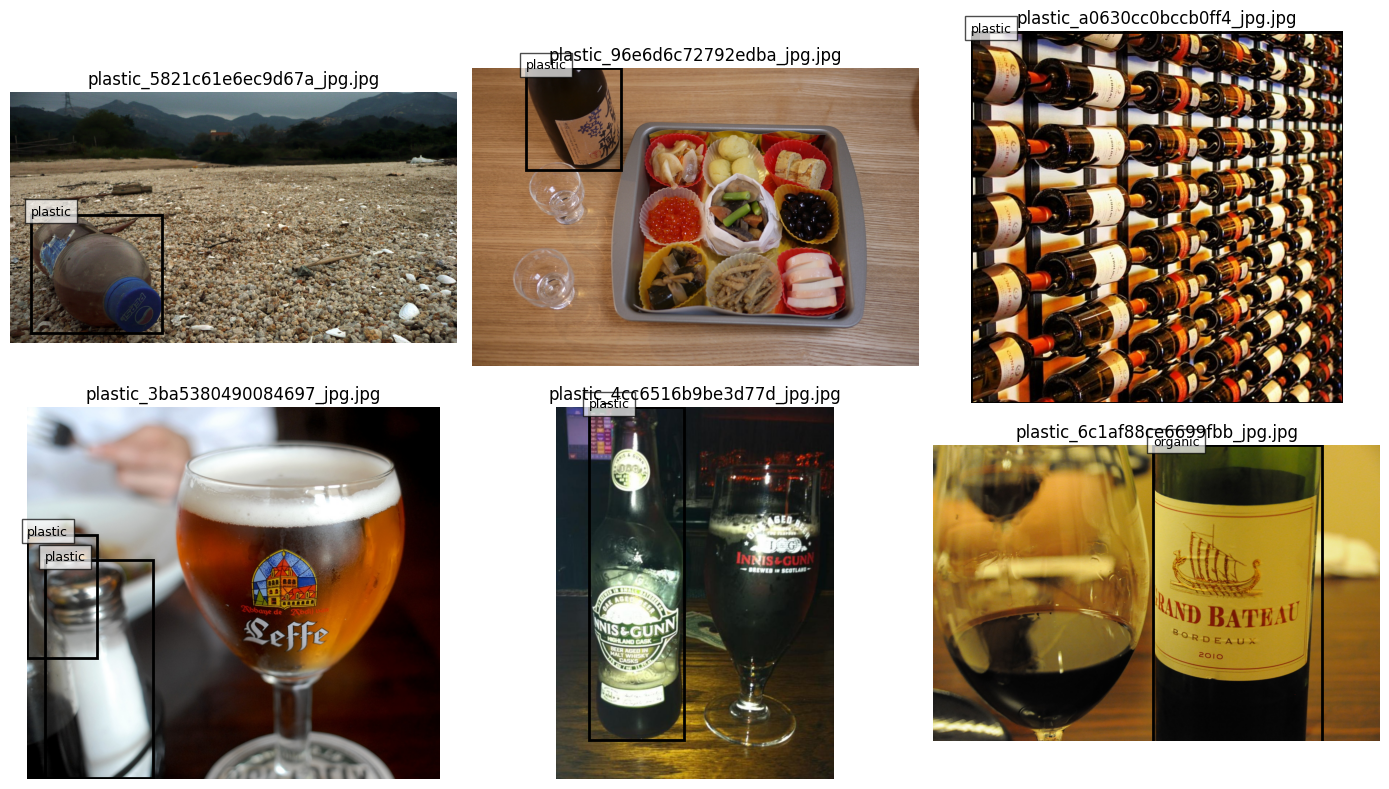

In [13]:
def show_samples(split="train", n=6):
    image_dir = DATASET_DIR / "images" / split
    images = list(image_dir.glob("*"))
    random.Random(SEED).shuffle(images)
    images = images[:n]

    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes = axes.flatten()

    for ax, img_path in zip(axes, images):
        img = Image.open(img_path).convert("RGB")
        ax.imshow(img)
        ax.set_title(img_path.name)
        ax.axis("off")

        label_path = DATASET_DIR / "labels" / split / f"{img_path.stem}.txt"
        if label_path.exists():
            W, H = img.size
            for line in label_path.read_text().splitlines():
                cls, xc, yc, w, h = map(float, line.split()[:5])
                x1 = (xc - w/2) * W
                y1 = (yc - h/2) * H
                bw = w * W
                bh = h * H
                rect = plt.Rectangle((x1, y1), bw, bh, fill=False, linewidth=2)
                ax.add_patch(rect)
                ax.text(x1, y1, CLASSES[int(cls)], fontsize=9,
                        bbox=dict(facecolor="white", alpha=0.7))

    plt.tight_layout()
    plt.show()

show_samples()


## 12. Train a small pretrained YOLO model

We start with a **small pretrained detection model** so the prototype can train quickly.

For a smoke test:
- `epochs=30` is enough to confirm the pipeline works.
- Later, the HPC run can use more epochs and a larger model if needed.

Do not judge final competition performance from this tiny prototype.


In [14]:
from ultralytics import YOLO

MODEL_NAME = "yolo26n.pt"

model = YOLO(MODEL_NAME)

results = model.train(
    data=str(yaml_path),
    epochs=30,
    imgsz=640,
    batch=-1,
    workers=0, # TODO: REMOVE THIS QUICK FIX and upgrade shared memory instead
    patience=10,
    project=str(PROJECT / "runs"),
    name="prototype",
    exist_ok=True,
)

print("Training finished.")


Ultralytics 8.4.156 🚀 Python-3.10.13 torch-2.1.0 CUDA:0 (NVIDIA RTX 4500 Ada Generation, 24117MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/workspace/waste_ai/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=prototype, nbs=64, nms=No

## 13. Validate the trained model

Validation answers:

> "How well does the model detect the classes on images it did not train on?"

Pay attention to:
- mAP50
- mAP50-95
- precision
- recall
- per-class performance

Do not look only at one overall number.


In [21]:
best_model_path = PROJECT / "runs" / "prototype" / "weights" / "best.pt"
# best_model_path =  "runs/detect/content/waste_ai/runs/prototype/weights/best.pt"
best_model = YOLO(str(best_model_path))

metrics = best_model.val(
    data=str(yaml_path),
    split="val",
    imgsz=640,
)

print("mAP50-95:", metrics.box.map)
print("mAP50:", metrics.box.map50)
print("Per-class mAP50-95:", metrics.box.maps)


Ultralytics 8.4.156 🚀 Python-3.10.13 torch-2.1.0 CUDA:0 (NVIDIA RTX 4500 Ada Generation, 24117MiB)
YOLO26n summary (fused): 120 layers, 2,375,421 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1308.0±280.3 MB/s, size: 297.1 KB)
val: Scanning /workspace/waste_ai/dataset/labels/val.cache... 28 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 28/28 1.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.1it/s 0.6s1.1s


ERROR: Unexpected bus error encountered in worker. This might be caused by insufficient shared memory (shm).
 

                   all         28        108      0.415       0.18      0.324      0.203
               plastic         12         66      0.564      0.121      0.468      0.279
                fabric         16         42      0.267      0.238       0.18      0.126
Speed: 2.2ms preprocess, 1.6ms inference, 0.0ms loss, 5.7ms postprocess per image
Results saved to /workspace/runs/detect/val-5
mAP50-95: 0.20257502934213764
mAP50: 0.323817410079677
Per-class mAP50-95: [    0.27943     0.12572     0.20258]


## 14. Test on completely unseen images

The test set should be treated as the final exam.

Do this after model development, not repeatedly while tuning the model.


In [22]:
test_metrics = best_model.val(
    data=str(yaml_path),
    split="test",
    imgsz=640,
)

print("TEST mAP50-95:", test_metrics.box.map)
print("TEST mAP50:", test_metrics.box.map50)
print("TEST per-class mAP50-95:", test_metrics.box.maps)


Ultralytics 8.4.156 🚀 Python-3.10.13 torch-2.1.0 CUDA:0 (NVIDIA RTX 4500 Ada Generation, 24117MiB)
YOLO26n summary (fused): 120 layers, 2,375,421 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 706.3±102.5 MB/s, size: 229.7 KB)
val: Scanning /workspace/waste_ai/dataset/labels/test.cache... 15 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 15/15 1.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.7it/s 0.2s
                   all         15         27      0.357      0.167      0.414      0.313
               plastic          7         16      0.409     0.0909      0.412      0.324
                fabric          8         11      0.305      0.242      0.417      0.302
Speed: 0.6ms preprocess, 1.2ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /workspace/runs/detect/val-6
TEST mAP50-95: 0.31271009455399057
TEST mAP50: 0.41432552303521897
TEST per-

## 15. Run inference on test images

Now look at what the robot would actually see.

The important question is not just "what is the metric?"

It is:

> **Does the model put the correct box around the correct waste object?**


In [23]:
test_images = list((DATASET_DIR / "images" / "test").glob("*"))

predictions = best_model.predict(
    source=[str(p) for p in test_images[:12]],
    imgsz=640,
    conf=0.25,
    save=True,
    project=str(PROJECT / "predictions"),
    name="test_predictions",
    exist_ok=True,
)

print("Prediction images saved to:", PROJECT / "predictions" / "test_predictions")



0: 640x640 (no detections), 0.9ms
1: 640x640 (no detections), 0.9ms
2: 640x640 (no detections), 0.9ms
3: 640x640 (no detections), 0.9ms
4: 640x640 (no detections), 0.9ms
5: 640x640 (no detections), 0.9ms
6: 640x640 (no detections), 0.9ms
7: 640x640 (no detections), 0.9ms
8: 640x640 (no detections), 0.9ms
9: 640x640 (no detections), 0.9ms
10: 640x640 (no detections), 0.9ms
11: 640x640 (no detections), 0.9ms
Speed: 1.3ms preprocess, 0.9ms inference, 0.1ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /workspace/waste_ai/predictions/test_predictions
Prediction images saved to: /workspace/waste_ai/predictions/test_predictions


## 16. Measure inference speed

Your camera is 30 FPS, but that does **not** mean the AI must necessarily run at 30 FPS.

For a robotics system, we first want a stable real-time perception loop. Benchmark the model on the **actual deployment computer** later.

This Colab timing is only a rough development benchmark.


In [24]:
import time

if test_images:
    sample = str(test_images[0])

    start = time.perf_counter()
    for _ in range(10):
        _ = best_model.predict(source=sample, imgsz=640, verbose=False)
    elapsed = time.perf_counter() - start

    fps = 10 / elapsed
    print(f"Approximate Colab inference throughput: {fps:.2f} FPS")
    print("This is NOT the final robot FPS.")


Approximate Colab inference throughput: 40.92 FPS
This is NOT the final robot FPS.


## 17. Save the model for the HPC

The important artifact is:

`best.pt`

Also save:
- `data.yaml`
- the dataset
- training results
- this notebook
- a requirements file
- a README describing the experiment

This makes the experiment reproducible on another computer.


In [25]:
requirements = 'ultralytics\nfiftyone\npyyaml\nnumpy\npillow\nmatplotlib\n'
(EXPORT_DIR / "requirements.txt").write_text(requirements)

# Copy the best model into a simple export location.
hpc_model = EXPORT_DIR / "best.pt"
shutil.copy2(best_model_path, hpc_model)

# Copy data.yaml
shutil.copy2(yaml_path, EXPORT_DIR / "data.yaml")

print("HPC model:", hpc_model)
print("Requirements:", EXPORT_DIR / "requirements.txt")


HPC model: /workspace/waste_ai/exports/best.pt
Requirements: /workspace/waste_ai/exports/requirements.txt


## 18. Package the project

The ZIP produced here can be transferred to the HPC system.

For a large real dataset, do not repeatedly copy the same dataset unnecessarily. Store the dataset in the HPC's designated storage area and keep the code/configuration under version control.


In [26]:
import zipfile

zip_path = EXPORT_DIR / "waste_ai_prototype_for_hpc.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    # Dataset
    for p in DATASET_DIR.rglob("*"):
        if p.is_file():
            z.write(p, p.relative_to(PROJECT))

    # Best model
    z.write(hpc_model, hpc_model.relative_to(PROJECT))

    # Requirements
    req = EXPORT_DIR / "requirements.txt"
    z.write(req, req.relative_to(PROJECT))

print("Package created:", zip_path)


Package created: /workspace/waste_ai/exports/waste_ai_prototype_for_hpc.zip


# What to improve next

### Version 1 — this notebook
Small proof of concept:
- 3 classes
- public proxy data
- pretrained YOLO
- Colab training
- validation
- test
- model export

### Version 2 — real objects
Replace the proxy classes with:
- actual plastic bottle photographs
- actual fabric waste/material photographs
- actual organic waste photographs

### Version 3 — competition environment
Collect images using the **actual robot camera** on the actual game field:
- field boards
- floor
- lighting
- shadows
- distance
- object placement
- screen/target information
- clutter

### Version 4 — robotics integration
Connect:

`camera → YOLO → object position → ROS2 → navigation/manipulation`

### Version 5 — HPC training
Move the same code/configuration to HPC:
- create the Python environment
- transfer/attach dataset
- use the HPC GPU
- run `train.py` as a batch job
- save checkpoints and `best.pt`

### Version 6 — deployment
Benchmark on the robot computer and decide whether you need:
- a smaller model,
- lower image size,
- ONNX,
- TensorRT,
- or another optimized deployment format.

### Version 7 — robustness
Add hard examples and repeat:
`collect → label → train → validate → inspect errors → collect more → retrain`.


# Experiment record

For every training run, record:

- Dataset version:
- Number of images:
- Images per class:
- Model:
- Epochs:
- Image size:
- Batch size:
- GPU:
- mAP50:
- mAP50-95:
- Precision:
- Recall:
- Per-class performance:
- Inference FPS:
- Main failure cases:
- What changed from the previous run:

This record is what will allow your team to compare HPC experiments instead of guessing which model was best.
